# 08 Knowledge graphs: a map that someone keeps

*Teaching material. Not for clinical use.*

The US military's resuscitation guideline is a source of edges. It says that whole blood is preferred, otherwise components at about 1:1:1, and that tranexamic acid is given as 2 g, only if started within 3 hours of injury. It was published on 12 July 2019 and updated in June and in August 2023 (E-86).

Suppose a system stored a tranexamic acid edge before those updates and has answered questions from it ever since.

**Before reading on, guess.** How would the system know whether its edge still held?

- It would know: a system keeps the latest version of what it was told
- It would not know: an edge says what it said when it was entered, until someone changes it
- It would know only if each edge carries its version and the date it holds from, and the question asks for them

Write the guess down. It is not marked, and the first failure below comes back to it.

In [1]:
%matplotlib inline
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch

from inference_labs import baseline
from inference_labs.lenses import knowledge as k
from inference_labs.lenses import rules

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 10, "axes.titleweight": "bold", "font.size": 9})
DARK, LIGHT, MID, PALE, GREY = "#7f2704", "#d9d9d9", "#08306b", "#6baed6", "#969696"
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", None)

## The idea, before any medicine

A map of the Underground is neither a rule nor a statistic. It does not say how long a journey takes or how crowded the train will be. It says which stations connect, on which line, and where to change. To find a route, follow the lines. Someone keeps the map: when a station closes or a line is extended, a person has to redraw it, and an old map, followed faithfully, still sends a traveller to the closed platform. A map is also drawn for some travellers and not others: a route with stairs at every change is a route for some.

The same idea has done diagnostic work at national scale. In a national genomics pilot, 4,660 participants had their clinical features coded as Human Phenotype Ontology terms, then sequencing with automated prioritisation; about 25% of probands received a diagnosis, 35% where a single-gene cause was likely against 11% where the cause was complex (E-107). Coding the features as shared terms was one step in that pipeline.

**Plain.** Some knowledge is neither a rule nor a statistic. It is a map of what connects to what, kept by people, with a source for every line. A question is answered by following the lines. The map's value and its danger have the same cause: people keep it. It holds what they put there, as they put it, until they change it.

**Developer.** Nodes are typed (finding, injury, intervention, competency, role, echelon) and keyed `type:name`. Each edge is typed (*suggests*, *treated by*, *requires*, *held by*, *available at*, and here *leads to* from one echelon to the next) and carries five fields: label, source, version, valid from and population. The graph also holds the MPTT-24's six steps, as threshold, observation and priority nodes joined by *tests* and *assigns* edges, which the diagnosis case comes to. A query is a traversal: start at a node, follow edges of the types asked for, and collect what is reached. The cost grows with the edges walked, and nothing is fitted. In the library, `knowledge.care_graph()` is the graph, `knowledge.diagnose_record(record)` ranks candidate injuries, `knowledge.chain(injury, start)` walks from an injury to the echelons, and `knowledge.as_of(src, dst, when)` and `knowledge.population_query(src, dst, population)` read the version and population fields.

**Technical.** A labelled property graph $G = (V, E)$ with typed vertices and edges, each edge carrying (label, source, version, valid_from, population). Diagnosis is a one-step traversal from the set $F$ of findings present, following only the edges whose condition $c(f, i)$, presenting with injury or with illness, matches the casualty's presentation $p$: injury $i$ scores $s(i) = \sum_{f \in F,\ (f, i) \in E,\ c(f, i) = p} 1/d^{+}(f)$, where $d^{+}(f)$ is the number of *suggests* edges leaving $f$, of either condition, a weight read from the graph alone; candidates are ranked by $s$, and equal scores are kept as ties. Treatment is a path query injury $\to$ intervention $\to$ competency $\to$ role $\to$ echelon, taking for each intervention the echelon earliest on the route. A date-aware query keeps the edges with valid_from $\le t$ and returns the newest; a population-aware query compares the edge's population with the casualty's. No probability is computed and nothing is learned: every answer is a function of the edges entered, so an edge that is missing or out of date gives a confident wrong answer.

The central figure is the graph's treatment half drawn as a route map. The control is the injury and where the casualty lies: change them and run the cell again.

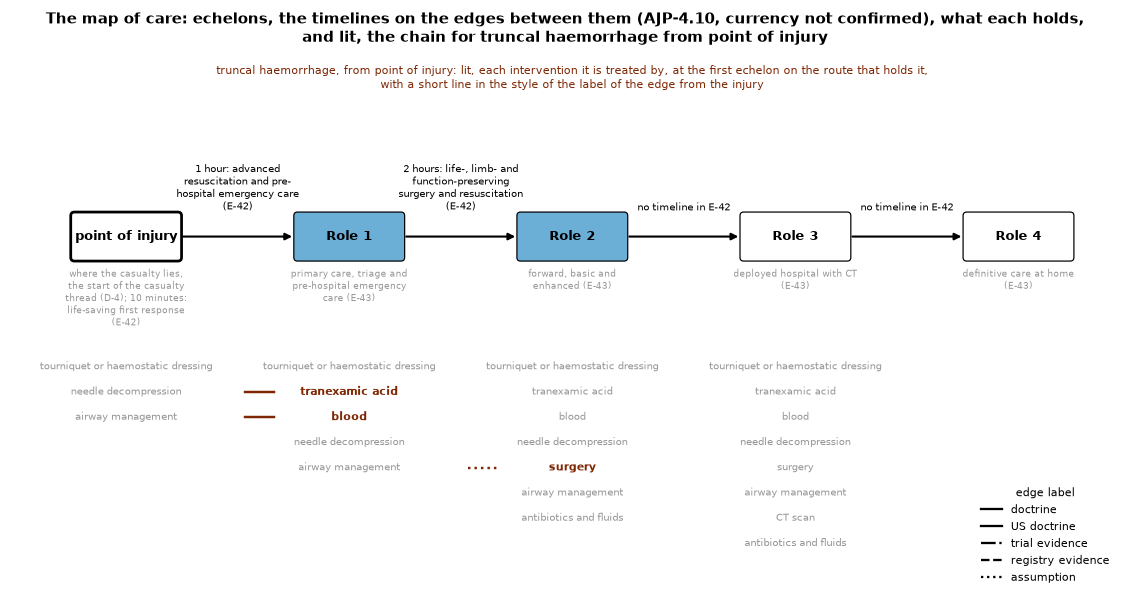

In [2]:
# Central figure: the map of care. The controls: change them and run the cell again.
INJURY = "truncal haemorrhage"     # any of k.INJURIES
START = "point of injury"          # where the casualty lies: any of k.ECHELONS

m = k.map_of_care(INJURY, START)
x = {e: 3.1 * n for n, e in enumerate(m["route"])}
lit = {(v, e): label for v, e, label in m["lit"] if e is not None}
short = {v: v.split(":")[0] for v in k.INTERVENTIONS}
fig, ax = plt.subplots(figsize=(13, 6.4))
for a, b, words, label in m["legs"]:
    ax.annotate("", (x[b] - 0.75, 0), (x[a] + 0.75, 0),
                arrowprops=dict(arrowstyle="-|>", color="black", lw=1.4, linestyle=k.EDGE_STYLES[label]))
    ax.text((x[a] + x[b]) / 2, 0.32, "\n".join(textwrap.wrap(words, 26)), ha="center", va="bottom", fontsize=6.6)
for e in m["route"]:
    behind = e in m["behind"]
    holds_lit = any(where == e for (_, where) in lit)
    ax.add_patch(FancyBboxPatch((x[e] - 0.72, -0.28), 1.44, 0.56, boxstyle="round,pad=0.05",
                                facecolor=LIGHT if behind else (PALE if holds_lit else "white"),
                                edgecolor=GREY if behind else "black", linewidth=1.8 if e == START else 0.8))
    ax.text(x[e], 0, e, ha="center", va="center", fontsize=8.5, weight="bold", color=GREY if behind else "black")
    what = k.ECHELON_WHAT[e] + ("; " + m["first response"] if e == k.POINT else "")
    ax.text(x[e], -0.42, "\n".join(textwrap.wrap(what, 26)), ha="center", va="top", fontsize=6.2, color=GREY)
    for j, v in enumerate(m["held"][e]):
        y = -1.75 - 0.34 * j
        on = (v, e) in lit
        ax.text(x[e], y, short[v], ha="center", va="center", fontsize=7.4 if on else 6.8,
                color=DARK if on else GREY, weight="bold" if on else "normal")
        if on:
            ax.plot([x[e] - 1.45, x[e] - 1.05], [y, y], color=DARK, lw=1.6, linestyle=k.EDGE_STYLES[lit[(v, e)]])
for v, e, label in m["lit"]:
    if e is None:
        print(f"{v}: not held on the route from {START}")
ax.text(x[k.ROLE2], 2.0, f"{INJURY}, from {START}: lit, each intervention it is treated by, at the first echelon on the "
        "route that holds it,\nwith a short line in the style of the label of the edge from the injury", ha="center",
        fontsize=7.5, color=DARK)
ax.legend(handles=[Line2D([], [], color="black", linestyle=s, label=l) for l, s in k.EDGE_STYLES.items()],
          loc="lower right", fontsize=7, title="edge label", title_fontsize=7, frameon=False)
ax.set_xlim(-1.6, x["Role 4"] + 1.4)
ax.set_ylim(-4.8, 2.5)
ax.axis("off")
ax.set_title(f"The map of care: echelons, the timelines on the edges between them (AJP-4.10, currency not confirmed), "
             f"what each holds,\nand lit, the chain for {INJURY} from {START}")
plt.show()

The stations from Role 1 to Role 4 are the roles of care of AJP-4.10, NATO doctrine (E-43); the point of injury, where the route starts, is the start of the casualty thread (D-4). The timelines on the edges are AJP-4.10's clinical timelines (E-42): 1 hour for advanced resuscitation and pre-hospital emergency care, 2 hours for life-, limb- and function-preserving surgery and resuscitation. The graph reads each as time from injury, an assumption. It places the 10 minutes for life-saving first response on the point of injury itself rather than on an edge, an assumption about where first response is given. Every edge from AJP-4.10 carries the edition read, Edition C Version 1, September 2019 (E-44), and the note that its currency was not confirmed (D-28).

The 1-hour timeline sits on the edge into Role 1, which holds pre-hospital emergency care (E-43). The 2-hour timeline sits on the edge into Role 2 because, in this graph, Role 2 is the first echelon holding surgery, and that placement is an assumption. Under each station is what the graph holds there: an intervention is held at an echelon when a role available there holds the competency it requires. Most of those edges are assumptions written for this lens; the figure draws the edge from injury to intervention in the style of its label. The chain for truncal haemorrhage lights tranexamic acid and blood at Role 1 and surgery at Role 2. Set `START = "Role 1"` and the point of injury greys out: the route runs one way.

## By hand: twelve nodes, from free fluid to the place that can treat it

Twelve nodes from the graph, one or more of each type:

| Type | Nodes |
|---|---|
| finding | free fluid on the scan |
| injury | truncal haemorrhage |
| intervention | tranexamic acid; surgery |
| competency | advanced resuscitation; operating |
| role | pre-hospital emergency care team; surgical team |
| echelon | point of injury; Role 1; Role 2; Role 3 |

**On paper.** Start at *free fluid on the scan*. One *suggests* edge leads to *truncal haemorrhage*. Three *treated by* edges lead on: two versions of the edge to *tranexamic acid*, which the first failure below takes up, and one to *surgery*. The edge list below keeps one entry for each pair of nodes, so it shows the two versions as one. Tranexamic acid *requires* advanced resuscitation, which is *held by* the pre-hospital emergency care team, which is *available at* Role 1. Surgery *requires* operating, *held by* the surgical team, *available at* Role 2 and at Role 3. Walk the route from the point of injury: Role 1 comes first, then Role 2. So tranexamic acid is first held at Role 1 and surgery at Role 2: two answers, from following edges, with no arithmetic.

The same trace follows: first in plain Python over the edges as a list of pairs, then by the library on the same twelve nodes. The three must agree.

In [3]:
edges = k.hand_edges()
display(pd.DataFrame(edges, columns=["from", "edge", "to"]))

# The same trace in plain Python, over the edge list
nxt = {}
for a, t, b in edges:
    nxt.setdefault((a, t), []).append(b)
route, here = ["point of injury"], "point of injury"
while (here, "leads_to") in nxt:
    here = nxt[(here, "leads_to")][0]
    route.append(here)
plain = set()
for injury in nxt[("free fluid on the scan", "suggests")]:
    for v in nxt[(injury, "treated_by")]:
        places = [e for c in nxt[(v, "requires")] for r in nxt[(c, "held_by")] for e in nxt[(r, "available_at")]]
        plain.add((v, min(places, key=route.index)))

on_paper = {("tranexamic acid", "Role 1"), ("surgery", "Role 2")}
library = set(map(tuple, k.trace("free fluid on the scan", k.hand_graph())[["intervention", "echelon"]].values))
print("plain Python:", sorted(plain))
print("library:     ", sorted(library))
print("on paper, plain Python and the library agree:", on_paper == plain == library)

,from,edge,to
0,free fluid on the scan,suggests,truncal haemorrhage
1,truncal haemorrhage,treated_by,tranexamic acid
2,truncal haemorrhage,treated_by,surgery
3,tranexamic acid,requires,advanced resuscitation
4,surgery,requires,operating
5,advanced resuscitation,held_by,pre-hospital emergency care team
6,operating,held_by,surgical team
7,pre-hospital emergency care team,available_at,Role 1
8,surgical team,available_at,Role 2
9,surgical team,available_at,Role 3


plain Python: [('surgery', 'Role 2'), ('tranexamic acid', 'Role 1')]
library:      [('surgery', 'Role 2'), ('tranexamic acid', 'Role 1')]
on paper, plain Python and the library agree: True


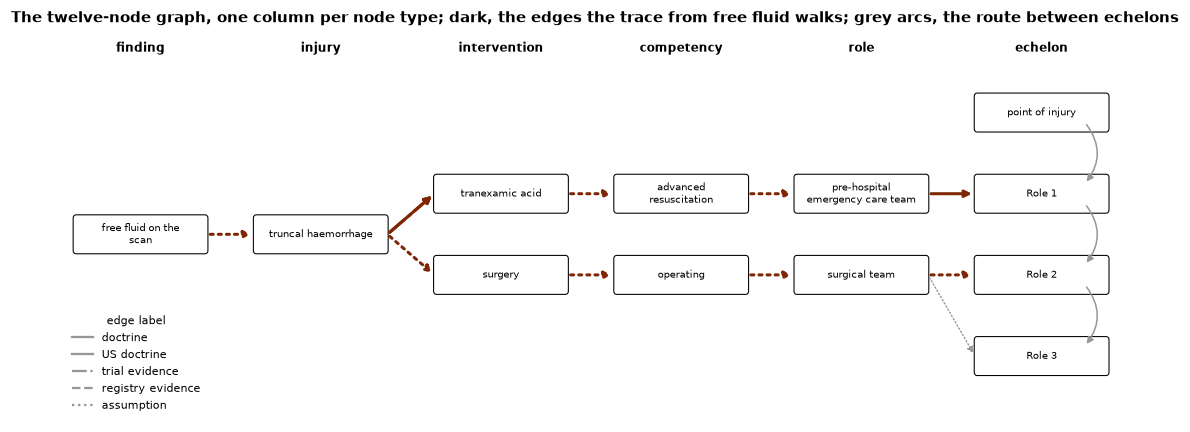

In [4]:
g = k.hand_graph()
columns = ["finding", "injury", "intervention", "competency", "role", "echelon"]
pos = {}
for c, t in enumerate(columns):
    keys = g.nodes(t)
    for r, key in enumerate(keys):
        pos[key] = (2.3 * c, (len(keys) - 1) / 2 - r)
trace = k.trace("free fluid on the scan", g)
on_trace = set()
for _, row in trace.iterrows():
    link = [l for l in k.chain(row["injury"], graph=g).links if l.intervention == row["intervention"]][0]
    on_trace |= {(link.edge.src, link.edge.dst)} | {(e.src, e.dst) for e in link.path}
on_trace.add(("finding:free fluid on the scan", "injury:truncal haemorrhage"))
fig, ax = plt.subplots(figsize=(12.5, 4.6))
for e in g.edges():
    (x0, y0), (x1, y1) = pos[e.src], pos[e.dst]
    hot = (e.src, e.dst) in on_trace
    if e.type == "leads_to":
        ax.annotate("", (x1 + 0.55, y1 + 0.12), (x0 + 0.55, y0 - 0.12),
                    arrowprops=dict(arrowstyle="-|>", color=GREY, lw=1.0, connectionstyle="arc3,rad=-0.4"))
        continue
    ax.annotate("", (x1 - 0.85, y1), (x0 + 0.85, y0),
                arrowprops=dict(arrowstyle="-|>", color=DARK if hot else GREY, lw=2.0 if hot else 0.9,
                                linestyle=k.EDGE_STYLES[e.label]))
for key, (xx, yy) in pos.items():
    ax.add_patch(FancyBboxPatch((xx - 0.82, yy - 0.2), 1.64, 0.4, boxstyle="round,pad=0.04", facecolor="white",
                                edgecolor="black", linewidth=0.7))
    ax.text(xx, yy, "\n".join(textwrap.wrap(k.name_of(key), 20)), ha="center", va="center", fontsize=6.6)
for c, t in enumerate(columns):
    ax.text(2.3 * c, 2.25, t, ha="center", fontsize=8, weight="bold")
ax.legend(handles=[Line2D([], [], color=GREY, linestyle=s, label=l) for l, s in k.EDGE_STYLES.items()],
          loc="lower left", fontsize=7, title="edge label", title_fontsize=7, frameon=False)
ax.set_xlim(-1, 12.6)
ax.set_ylim(-2.3, 2.5)
ax.axis("off")
ax.set_title("The twelve-node graph, one column per node type; dark, the edges the trace from free fluid walks; "
             "grey arcs, the route between echelons")
plt.show()

## Diagnosis: from findings to candidate injuries

A record is coded into the graph's terms first: nine findings, each a yes or no read from what a medic would have. The thresholds are taken where the register has them: heart rate and respiratory rate from the MPTT-24's steps (E-08), systolic pressure under 100 from the US guideline's massive transfusion predictors (E-86, US doctrine, not UK practice). A finding *suggests* an injury along an edge. There are 28 such edges, each running from a finding to a condition that, in the generator, makes the finding more likely, and each followed only for a casualty presenting as it says, with injury or with illness. Every one is an assumption written for this lens.

The six candidate injuries are the generator's four kinds of need for a life-saving intervention, with bleeding split by site: extremity, junctional and truncal haemorrhage, tension pneumothorax, severe head injury and septic shock. A casualty has at most one of them.

The output is a ranked list, not one answer. The DDXPlus data set holds about 1.3 million synthetic patients, 49 pathologies, 110 symptoms and 113 antecedents, each patient with a differential diagnosis rather than a single answer, generated from a proprietary knowledge base and a commercial rule-based system (E-51). The knowledge base is proprietary, so, as this notebook reads it, a user cannot trace a differential back to the edges that produced it. Here every edge carries its source, and every candidate the edges that produced it.

The ranking is the graph's own. Each finding present adds one over the number of injuries it suggests: free fluid on the scan suggests one injury and adds 1; heart rate 100 or more suggests five and adds a fifth to each. Equal scores are reported as ties, not broken.

In [5]:
weights = pd.DataFrame([{"finding": f.name, "threshold from": f.threshold_from, "injuries suggested": k.out_degree(f.name),
                         "adds to each": f"1/{k.out_degree(f.name)}"} for f in k.FINDINGS]).set_index("finding")
display(weights)

observed, truth = baseline.generator_sample("pre_hospital")
cond = k.true_condition(truth)
found = k.findings(observed)
i = int(np.flatnonzero((cond == "truncal haemorrhage") & found["free fluid on the scan"].to_numpy())[0])
d = k.diagnose_record(observed.iloc[i].to_dict())
print(f"Synthetic casualty {observed['id'].iloc[i]}, {d.context}, scan before hospital. Findings: {', '.join(d.findings)}.")
for c in d.candidates:
    print(f"  {c.rank}. {c.injury}: score {c.score:.3f}{' (tied)' if c.tied > 1 else ''}")
    for e in c.edges:
        print(f"       {k.name_of(e.src)} -> {k.name_of(e.dst)}  [{e.label}; adds 1/{k.out_degree(k.name_of(e.src))}]")
print(f"The generator's truth for this casualty: {cond[i]}.")

,threshold from,injuries suggested,adds to each
finding,,,
catastrophic haemorrhage,"E-08, the first step",2,1/2
free fluid on the scan,the scan's own reading,1,1/1
pneumothorax on the scan,the scan's own reading,1,1/1
heart rate 100 or more,E-08: below 100 gives Priority 2,5,1/5
respiratory rate 24 or more,E-08: 12 to 23 passes,5,1/5
respiratory rate below 12,E-08: 12 to 23 passes,1,1/1
systolic pressure under 100,"E-86, US doctrine: a massive transfusion predictor",3,1/3
below alert,the AVPU scale,4,1/4
not walking,"E-08, the second step",6,1/6


Synthetic casualty 93, presenting with injury, scan before hospital. Findings: free fluid on the scan, respiratory rate 24 or more, systolic pressure under 100, not walking.
  1. truncal haemorrhage: score 1.700
       free fluid on the scan -> truncal haemorrhage  [assumption; adds 1/1]
       respiratory rate 24 or more -> truncal haemorrhage  [assumption; adds 1/5]
       systolic pressure under 100 -> truncal haemorrhage  [assumption; adds 1/3]
       not walking -> truncal haemorrhage  [assumption; adds 1/6]
  2. extremity haemorrhage: score 0.700 (tied)
       respiratory rate 24 or more -> extremity haemorrhage  [assumption; adds 1/5]
       systolic pressure under 100 -> extremity haemorrhage  [assumption; adds 1/3]
       not walking -> extremity haemorrhage  [assumption; adds 1/6]
  2. junctional haemorrhage: score 0.700 (tied)
       respiratory rate 24 or more -> junctional haemorrhage  [assumption; adds 1/5]
       systolic pressure under 100 -> junctional haemorrhage  [as

In [6]:
r = k.diagnosis_results("pre_hospital")
print(f"{r['casualties']:,} synthetic casualties of the military cohort (seed 42), scan before hospital; "
      f"{r['with a condition']:,} have a condition needing a life-saving intervention.")
for name in k.LIST_MEASURES:
    print(f"  true condition {name}: {100 * r[name]:.1f}%")
print(f"The flag 'any candidate' marks {100 * r['flag'].mean():.1f}% of all casualties, against {100 * r['need'].mean():.1f}% in need.")
for who, m in (("graph, any candidate", r["flag metrics"]), ("MPTT-24, figure (as published)", r["figure"]),
               ("MPTT-24, text (as validated)", r["text"])):
    print(f"  {who}: sensitivity {100 * m['sensitivity']:.1f}%, specificity {100 * m['specificity']:.1f}%")
spread = k.diagnosis_spread("pre_hospital")
print("Graph less MPTT-24 (figure), sensitivity:", k.spread_words(100 * spread["sensitivity, graph less rule"], 1, " points"))
print("Graph less MPTT-24 (figure), specificity:", k.spread_words(100 * spread["specificity, graph less rule"], 1, " points"))
print(rules.d23_sentence())
display(k.by_condition("pre_hospital"))
display(k.by_condition("in_hospital"))

100,000 synthetic casualties of the military cohort (seed 42), scan before hospital; 16,704 have a condition needing a life-saving intervention.
  true condition first, alone: 21.7%
  true condition first, alone or tied: 85.3%
  true condition anywhere in the list: 95.0%
The flag 'any candidate' marks 71.9% of all casualties, against 16.7% in need.
  graph, any candidate: sensitivity 95.7%, specificity 32.8%
  MPTT-24, figure (as published): sensitivity 60.0%, specificity 78.6%
  MPTT-24, text (as validated): sensitivity 61.4%, specificity 77.8%


Graph less MPTT-24 (figure), sensitivity: higher: the difference runs from +35.2 to +36.4 points across 20 seeds
Graph less MPTT-24 (figure), specificity: lower: the difference runs from -46.4 to -45.7 points across 20 seeds
The scorecard's figures are on every stream of the military cohort, disease included; the comparison with E-09 holds for the injured only, of whom 26.5% need a life-saving intervention against 47.6% Priority 1 in the military registry (E-09), so the generator's injured are a milder cohort than the one the rule was validated on (D-23).


,casualties,"first, alone","first, alone or tied",anywhere in the list
extremity haemorrhage,5397.0,0.000,0.891,0.966
junctional haemorrhage,1632.0,0.000,0.888,0.960
truncal haemorrhage,3805.0,0.251,0.934,0.964
tension pneumothorax,1822.0,0.329,0.905,0.975
severe head injury,2360.0,0.273,0.578,0.939
septic shock,1688.0,0.845,0.845,0.845


,casualties,"first, alone","first, alone or tied",anywhere in the list
extremity haemorrhage,5397.0,0.000,0.938,0.966
junctional haemorrhage,1632.0,0.000,0.934,0.960
truncal haemorrhage,3805.0,0.733,0.985,0.988
tension pneumothorax,1822.0,0.661,0.957,0.986
severe head injury,2360.0,0.281,0.595,0.939
septic shock,1688.0,0.845,0.845,0.845


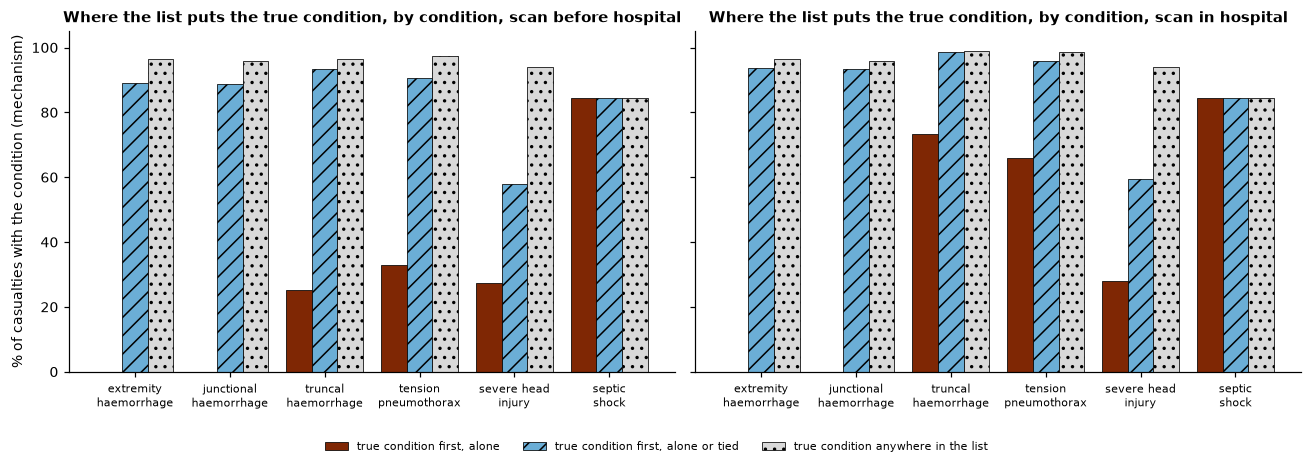

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
shades = (DARK, PALE, LIGHT)
hatches = ("", "//", "..")
for ax, setting in zip(axes, k.SETTINGS):
    table = k.by_condition(setting)
    xs = np.arange(len(table))
    for j, name in enumerate(k.LIST_MEASURES):
        ax.bar(xs + (j - 1) * 0.27, 100 * table[name], 0.27, color=shades[j], hatch=hatches[j], edgecolor="black",
               linewidth=0.5, label=f"true condition {name}")
    ax.set_xticks(xs, ["\n".join(textwrap.wrap(c, 11, break_long_words=False)) for c in table.index], fontsize=7.5)
    ax.set_title(f"Where the list puts the true condition, by condition, {k.SETTING_NAMES[setting]}")
    ax.set_ylim(0, 105)
axes[0].set_ylabel("% of casualties with the condition (mechanism)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, fontsize=7.5, frameon=False, loc="lower center", ncol=3)
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

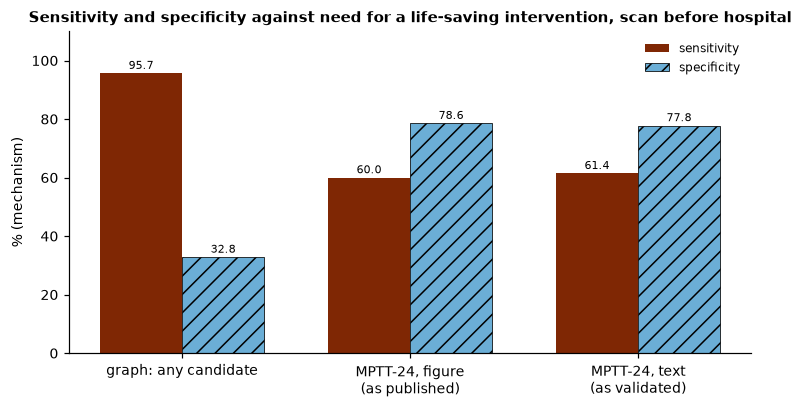

In [8]:
r = k.diagnosis_results("pre_hospital")
who = (("graph: any candidate", r["flag metrics"]), ("MPTT-24, figure\n(as published)", r["figure"]),
       ("MPTT-24, text\n(as validated)", r["text"]))
fig, ax = plt.subplots(figsize=(8, 3.8))
xs = np.arange(len(who))
ax.bar(xs - 0.18, [100 * m["sensitivity"] for _, m in who], 0.36, color=DARK, label="sensitivity")
ax.bar(xs + 0.18, [100 * m["specificity"] for _, m in who], 0.36, color=PALE, hatch="//", edgecolor="black",
       linewidth=0.5, label="specificity")
for x0, (_, m) in zip(xs, who):
    ax.text(x0 - 0.18, 100 * m["sensitivity"] + 1.5, f"{100 * m['sensitivity']:.1f}", ha="center", fontsize=7.5)
    ax.text(x0 + 0.18, 100 * m["specificity"] + 1.5, f"{100 * m['specificity']:.1f}", ha="center", fontsize=7.5)
ax.set_xticks(xs, [w for w, _ in who])
ax.set_ylim(0, 110)
ax.set_ylabel("% (mechanism)")
ax.legend(frameon=False, fontsize=8, loc="upper right")
ax.set_title("Sensitivity and specificity against need for a life-saving intervention, scan before hospital")
plt.show()

The list holds the true condition for 95.0% of the 16,704 casualties with one, puts it first, alone or tied, for 85.3%, and alone at the top for only 21.7%. The split by condition says why. Extremity and junctional haemorrhage are never alone at the top: every finding that suggests one suggests the other, so nothing in the record separates them, and the graph says so with a tie rather than a guess. Truncal haemorrhage is alone at the top for 25.1% before hospital and 73.3% in hospital, because only the scan for free fluid separates it from the other two sites, and the generator's scan finds free fluid far more often in hospital, set from a pooled analysis of in-hospital studies, 52 of them for free fluid within 75 studies of 24,350 patients (E-14), than before it, set from a civilian helicopter service (E-16). Applying either to the generator's battle casualties is an assumption. Septic shock reads the same at 84.5% on every measure: for a casualty presenting with illness the graph holds one candidate, so whenever any of its three findings is present the list is that one candidate alone.

As a flag, "any candidate" marks 71.9% of all casualties against 16.7% in need. Its sensitivity is 95.7% and its specificity 32.8%, against the MPTT-24's 60.0% and 78.6% under the figure reading (61.4% and 77.8% under the text reading). Across 20 further samples the graph's sensitivity is higher by 35.2 to 36.4 points and its specificity lower by 45.7 to 46.4. The graph lists whatever its edges connect; it was not built to say who needs help, and a list is not a decision. The rule's accuracy here is on the generator. The scorecard's figures are on every stream of the military cohort, disease included; the comparison with E-09 holds for the injured only, of whom 26.5% need a life-saving intervention against 47.6% Priority 1 in the military registry (E-09), so the generator's injured are a milder cohort than the one the rule was validated on (D-23). The generator's physiology is an assumption, tuned until the rule landed within 0.05 of E-09's accuracy, which was measured on first recorded hospital respiratory rate and registry GCS, not at the point of injury.

Every one of these results is a mechanism: the 28 *suggests* edges were written from what the generator's code does, and the graph is scored on the world those edges describe.

### The baseline is also a graph

The MPTT-24's six steps, as published (E-08), are edges too: each step a threshold node that *tests* an observation and *assigns* a priority on one answer. Run as a traversal, taking the thresholds in step order, the graph must give the same priority as the coded rule on every casualty, under each reading of the voice step. The generator records no breathing check, so the traversal, like the coded rule, takes every casualty as breathing: an assumption.

In [9]:
edges = k.edge_table()
display(edges[edges["type"].isin(["tests", "assigns"])][["from", "type", "to", "label", "source"]])
display(k.rule_agreement())

,from,type,to,label,source
85,catastrophic haemorrhage,tests,catastrophic haemorrhage,registry evidence,E-08
86,catastrophic haemorrhage,assigns,Priority 1,registry evidence,E-08
87,walking,tests,walking,registry evidence,E-08
88,walking,assigns,Priority 3,registry evidence,E-08
89,breathing,tests,breathing,registry evidence,E-08
90,breathing,assigns,Dead,registry evidence,E-08
91,responds to voice,tests,responds to voice,registry evidence,E-08
92,responds to voice,assigns,Priority 1,registry evidence,E-08
93,respiratory rate 12 to 23,tests,respiratory rate,registry evidence,E-08
94,respiratory rate 12 to 23,assigns,Priority 1,registry evidence,E-08


,casualties,agree
reading,,
figure,100000,100000
text,100000,100000


## Treatment: injury to intervention to competency to role to echelon

The second traversal starts at an injury. It follows *treated by* edges to interventions, *requires* to competencies, *held by* to roles and *available at* to echelons, and for each intervention takes the echelon earliest on the route from where the casualty lies. The timeline is read from the edge into that echelon.

Where two versions of an edge join the same pair of nodes, the chain uses the date-aware query and, where two are equally new, the population-aware one; the failures below show why. So the tranexamic acid edge in the chain is the US guideline's, 2 g only if started within 3 hours of injury (E-86, US doctrine, not UK practice).

In [10]:
for link in k.chain("truncal haemorrhage").links:
    e = link.edge
    print(f"{link.intervention}")
    print(f"    treated by: {k.shown_label(e)}; {e.source}; {e.version}; valid from {e.valid_from}; population: {e.population}")
    if "dose" in e.props:
        print(f"    dose: {e.props['dose']}, {e.props['condition']}")
    for note in link.notes:
        print(f"    {note}")
    print(f"    requires {link.competency}; held by the {link.role}; first held at {link.echelon}: {link.timeline}")
    for p in link.path:
        print(f"        {k.name_of(p.src)} -> {k.name_of(p.dst)} [{p.label}{', ' + p.source if p.label != 'assumption' else ''}]")

tranexamic acid
    treated by: US doctrine; E-86; US Joint Trauma System guideline, published 12 July 2019, with rapid updates in June and August 2023, as read (E-86); valid from 2023-08; population: US military casualties (US doctrine, not UK practice)
    dose: 2 g, only if started within 3 hours of injury
    1 earlier version set aside
    requires advanced resuscitation; held by the pre-hospital emergency care team; first held at Role 1: 1 hour: advanced resuscitation and pre-hospital emergency care (E-42)
        tranexamic acid -> advanced resuscitation [assumption]
        advanced resuscitation -> pre-hospital emergency care team [assumption]
        pre-hospital emergency care team -> Role 1 [doctrine, E-43]
blood: whole blood, otherwise components at about 1:1:1
    treated by: US doctrine; E-86; US Joint Trauma System guideline, published 12 July 2019, with rapid updates in June and August 2023, as read (E-86); valid from 2023-08; population: US military casualties (US doc

,condition,casualties,intervention,edge label,echelon,timeline,share within the timeline
0,extremity haemorrhage,5397,tourniquet or haemostatic dressing,assumption,point of injury,10 minutes: life-saving first response (E-42),NaN
1,extremity haemorrhage,5397,tranexamic acid,US doctrine,Role 1,1 hour: advanced resuscitation and pre-hospital emergency care (E-42),0.554
2,extremity haemorrhage,5397,"blood: whole blood, otherwise components at about 1:1:1",US doctrine,Role 1,1 hour: advanced resuscitation and pre-hospital emergency care (E-42),0.554
3,junctional haemorrhage,1632,tourniquet or haemostatic dressing,assumption,point of injury,10 minutes: life-saving first response (E-42),NaN
4,junctional haemorrhage,1632,tranexamic acid,US doctrine,Role 1,1 hour: advanced resuscitation and pre-hospital emergency care (E-42),0.551
5,junctional haemorrhage,1632,"blood: whole blood, otherwise components at about 1:1:1",US doctrine,Role 1,1 hour: advanced resuscitation and pre-hospital emergency care (E-42),0.551
6,junctional haemorrhage,1632,surgery,assumption,Role 2,"2 hours: life-, limb- and function-preserving surgery and resuscitation (E-42)",0.582
7,truncal haemorrhage,3805,tranexamic acid,US doctrine,Role 1,1 hour: advanced resuscitation and pre-hospital emergency care (E-42),0.557
8,truncal haemorrhage,3805,"blood: whole blood, otherwise components at about 1:1:1",US doctrine,Role 1,1 hour: advanced resuscitation and pre-hospital emergency care (E-42),0.557
9,truncal haemorrhage,3805,surgery,assumption,Role 2,"2 hours: life-, limb- and function-preserving surgery and resuscitation (E-42)",0.603


The generator times tranexamic acid at pre-hospital care. Of its 10,834 battle casualties bleeding significantly, that time falls within the US guideline's 3 hours (E-86) for 99.0% and within the 8 hours of CRASH-2 (E-19), a civilian trial whose window is applied to battle casualties here as an assumption, for 100.0%.


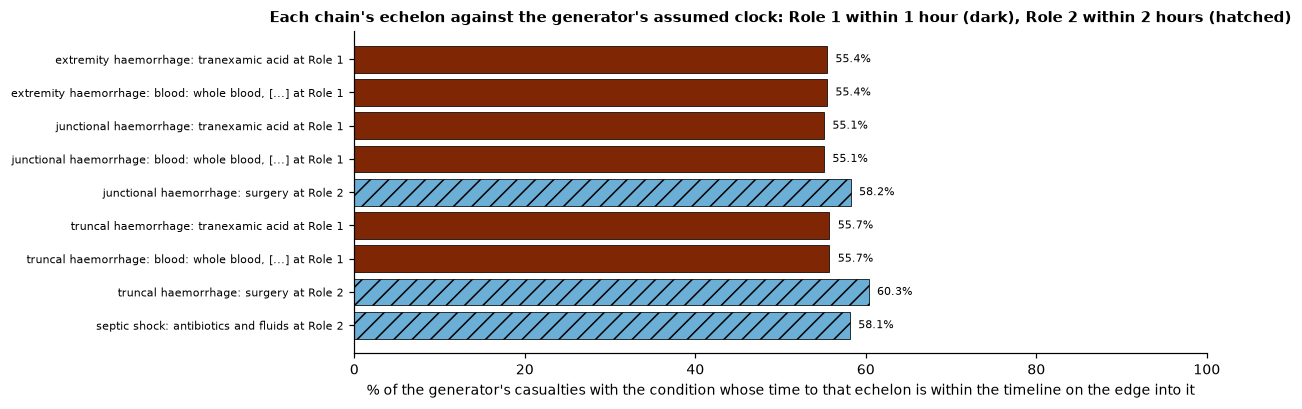

In [11]:
table = k.treatment_table()
display(table)
windows = k.txa_windows()
print(f"The generator times tranexamic acid at pre-hospital care. Of its {windows['casualties']:,} battle casualties "
      f"bleeding significantly, that time falls within the US guideline's 3 hours (E-86) for {100 * windows['E-86']:.1f}% "
      f"and within the 8 hours of CRASH-2 (E-19), a civilian trial whose window is applied to battle casualties here "
      f"as an assumption, for {100 * windows['CRASH-2']:.1f}%.")

timed = table.dropna(subset=["share within the timeline"]).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10, 3.8))
ys = np.arange(len(timed))[::-1]
ax.barh(ys, 100 * timed["share within the timeline"], color=[DARK if e == "Role 1" else PALE for e in timed["echelon"]],
        edgecolor="black", linewidth=0.5, hatch=["" if e == "Role 1" else "//" for e in timed["echelon"]])
ax.set_yticks(ys, [f"{r.condition}: {textwrap.shorten(r.intervention, 28)} at {r.echelon}" for r in timed.itertuples()],
              fontsize=7.5)
for y, v in zip(ys, timed["share within the timeline"]):
    ax.text(100 * v + 1, y, f"{100 * v:.1f}%", va="center", fontsize=7.5)
ax.set_xlim(0, 100)
ax.set_xlabel("% of the generator's casualties with the condition whose time to that echelon is within the timeline on the edge into it")
ax.set_title("Each chain's echelon against the generator's assumed clock: Role 1 within 1 hour (dark), Role 2 within 2 "
             "hours (hatched)")
plt.show()

For truncal haemorrhage the chain reaches tranexamic acid and blood at Role 1, through the pre-hospital emergency care team, and surgery at Role 2, through the surgical team. On the generator, 55.7% of the 3,805 casualties bleeding into the trunk have a time to pre-hospital care within the hour on the edge into Role 1, and 60.3% a time to Role 2 within its 2 hours, each timeline read as time from injury, an assumption. The generator draws these times for every casualty, including those it has dead from bleeding before then, so the shares are of times, not of arrivals. The timeline belongs to the edge, as E-42 states it, and is not a target for each intervention; for septic shock, the 2 hours on the edge into Role 2 is a timeline for surgery and resuscitation, not for antibiotics. The generator's times to pre-hospital care and to Role 2 are assumptions, and time to pre-hospital care stands in for reaching Role 1. The generator holds no time for care at the point of injury or for reaching Role 3, so the tourniquet, the needle, the airway and the CT scan have no share.

The generator times tranexamic acid at pre-hospital care, and for 99.0% of its 10,834 battle casualties bleeding significantly that time falls within the US guideline's 3 hours. The window on the edge is checked against the generator's clock, and the clock is an assumption.

The graph says what is held where and how long the doctrine allows. It does not say whether a casualty arrives in time; that is a question for the generator's clock, or for the stochastic lens.

### What can be done here

A query for what an echelon holds returns every intervention whose competency is held by a role available there. It is offered as a bound on the options a decision may consider. The decision theory lens chooses which of two casualties an aircraft takes to surgery first; asked at Role 1, this graph does not hold surgery, so a choice to operate there would lie outside what the graph holds. The decision theory lens is not changed to use the query.

point of injury: 3 interventions
Role 1: 5 interventions
Role 2: 7 interventions
Role 3: 8 interventions
Role 4: 0 interventions


,intervention,competency,role,labels
0,tourniquet or haemostatic dressing,control of severe bleeding,pre-hospital emergency care team,"assumption, doctrine"
1,tranexamic acid,advanced resuscitation,pre-hospital emergency care team,"assumption, doctrine"
2,"blood: whole blood, otherwise components at about 1:1:1",transfusion,pre-hospital emergency care team,"assumption, doctrine"
3,needle decompression,chest decompression,pre-hospital emergency care team,"assumption, doctrine"
4,airway management,"airway, breathing and circulation",pre-hospital emergency care team,"assumption, doctrine"


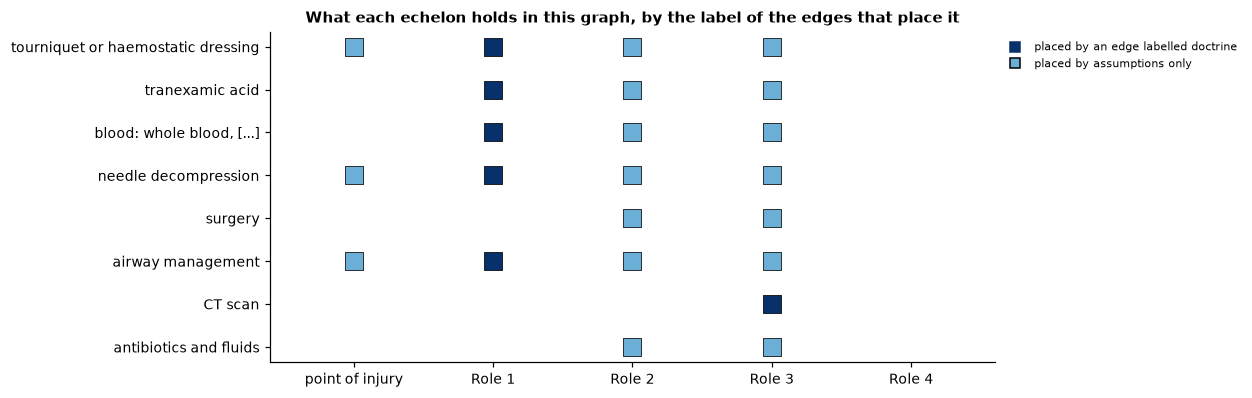

In [12]:
held = {e: k.options_at(e) for e in k.ECHELONS}
for e, frame in held.items():
    print(f"{e}: {len(frame)} intervention{'s' if len(frame) != 1 else ''}")
display(held["Role 1"])

grid = np.array([[v in set(held[e]["intervention"]) for e in k.ECHELONS] for v in k.INTERVENTIONS])
fig, ax = plt.subplots(figsize=(8.5, 3.9))
for a, v in enumerate(k.INTERVENTIONS):
    for b, e in enumerate(k.ECHELONS):
        if grid[a, b]:
            labels = held[e].set_index("intervention").loc[v, "labels"]
            doctrine = "doctrine" in labels
            ax.scatter(b, a, s=150, marker="s", color=MID if doctrine else PALE, edgecolor="black", linewidth=0.5)
ax.set_xticks(range(len(k.ECHELONS)), k.ECHELONS)
ax.set_yticks(range(len(k.INTERVENTIONS)), [textwrap.shorten(v, 34) for v in k.INTERVENTIONS])
ax.invert_yaxis()
ax.set_xlim(-0.6, len(k.ECHELONS) - 0.4)
ax.legend(handles=[Line2D([], [], marker="s", linestyle="", color=MID, label="placed by an edge labelled doctrine"),
                   Line2D([], [], marker="s", linestyle="", color=PALE, markeredgecolor="black",
                          label="placed by assumptions only")], fontsize=7, frameon=False, loc="upper left",
          bbox_to_anchor=(1.0, 1.0))
ax.set_title("What each echelon holds in this graph, by the label of the edges that place it")
plt.show()

The point of injury holds three interventions, Role 1 five, Role 2 seven and Role 3 eight; Role 4 holds none, because no role in this graph is available there. Most placements rest on assumptions alone. Two available-at edges come from AJP-4.10, the pre-hospital emergency care team at Role 1 and the radiology team at Role 3 (E-43), and only they carry the label doctrine. E-43's row records what Role 1 and Role 3 provide, pre-hospital emergency care and a hospital with CT, not these teams: the names of the teams are this graph's own, an assumption. The bound is as good as the edges behind it.

## The failure: an edge out of date, and an edge for another population

### First, provenance

The same store holds a second graph: every generator parameter as a node, joined by a *taken from* edge to its source, and each notebook as a node holding its evidence list. Two questions can be put to it. Where does each parameter come from? And which results depend on E-16, the scan accuracy before hospital, measured in a civilian helicopter service and applied to the generator's battle casualties as an assumption?

In [13]:
sources = k.parameter_sources()
print(sources["label"].value_counts().to_string())
with pd.option_context("display.width", 250):
    print(sources[sources["label"] != "assumption"].to_string())
print("E-16 is a civilian helicopter service; E-22 and E-24 come from CRASH-2, a civilian trial, E-24 pooled with WOMAN.")
print("Depends on E-16, the civilian helicopter service's scan accuracy:", k.depends_on("E-16"))

label
assumption           28
registry evidence     9
trial evidence        2
                                      source              label                                                               population
parameter                                                                                                                               
stream_shares               E-34, E-35, E-36  registry evidence  UK Service personnel admitted to field hospitals, Afghanistan 2006-2014
battle_mechanism                        E-35  registry evidence                       UK battle injury admissions, Afghanistan 2006-2014
non_battle_mechanism                    E-35  registry evidence                   UK non-battle injury admissions, Afghanistan 2006-2014
triage_accuracy_military                E-09  registry evidence                                         UK Joint Theatre Trauma Registry
triage_accuracy_civilian                E-09  registry evidence                     Trauma Audit and

Of the 39 generator parameters, 28 are assumptions, 9 carry the label registry evidence and 2 the label trial evidence. E-16, from a civilian helicopter service, supplies one parameter, the scan's accuracy before hospital, which the generator applies to its battle casualties as an assumption, and the notebooks whose evidence lists name it are returned.

The query answers from what the graph holds, and no more. Notebooks 04 and 10 both use the generator's scan for free fluid, whose accuracy before hospital is set from E-16, and neither names E-16 in its evidence list, so neither is returned. The graph holds what each notebook cites, not what its code reads, and only an edge for the second would catch them. A provenance graph is only as complete as the edges someone entered.

### Failure one: a stale edge

The graph holds two versions of the edge from significant bleeding to tranexamic acid, entered in the order a graph kept over the years would have entered them. The earlier is the CRASH-2 regimen: 1 g over 10 minutes then 1 g over 8 hours, in 20,211 trauma patients randomised within 8 hours of injury in 274 hospitals in 40 countries, entered by clinical judgement (E-19, E-20). It is a civilian trial and the edge says so. The later is the US guideline's: 2 g, only if started within 3 hours of injury (E-86), US doctrine.

The register records that the guideline was published on 12 July 2019 and updated in June and August 2023 (E-86). It holds neither the guideline's earlier wording nor which update set the dose, so the earlier edge is the CRASH-2 regimen, not an earlier version of the guideline, and the later edge carries the date of the latest update in the version read, August 2023.

In [14]:
src, dst = "injury:truncal haemorrhage", "intervention:tranexamic acid"
naive = k.first_found(src, dst)
print(f"Ignoring versions: {naive.props['dose']}, {naive.props['condition']} ({k.shown_label(naive)}; {naive.source}; valid from "
      f"{naive.valid_from}; population: {naive.population})")
for when in ("2020-01-01", k.TODAY):
    d = k.as_of(src, dst, when)
    print(f"As of {when}: {d.edge.props['dose']}, {d.edge.props['condition']} ({k.shown_label(d.edge)}; {d.edge.source}; valid "
          f"from {d.edge.valid_from}; population: {d.edge.population}); earlier versions {len(d.earlier)}, later "
          f"versions {len(d.later)}")

Ignoring versions: 1 g over 10 minutes, then 1 g over 8 hours, within 8 hours of injury, on clinical judgement (trial evidence; E-19, E-20; valid from 2010; population: civilian trauma patients entered by clinical judgement within 8 hours of injury, 274 hospitals in 40 countries (E-19, E-20))
As of 2020-01-01: 1 g over 10 minutes, then 1 g over 8 hours, within 8 hours of injury, on clinical judgement (trial evidence; E-19, E-20; valid from 2010; population: civilian trauma patients entered by clinical judgement within 8 hours of injury, 274 hospitals in 40 countries (E-19, E-20)); earlier versions 0, later versions 1
As of 2026-11-14: 2 g, only if started within 3 hours of injury (US doctrine; E-86; valid from 2023-08; population: US military casualties (US doctrine, not UK practice)); earlier versions 1, later versions 0


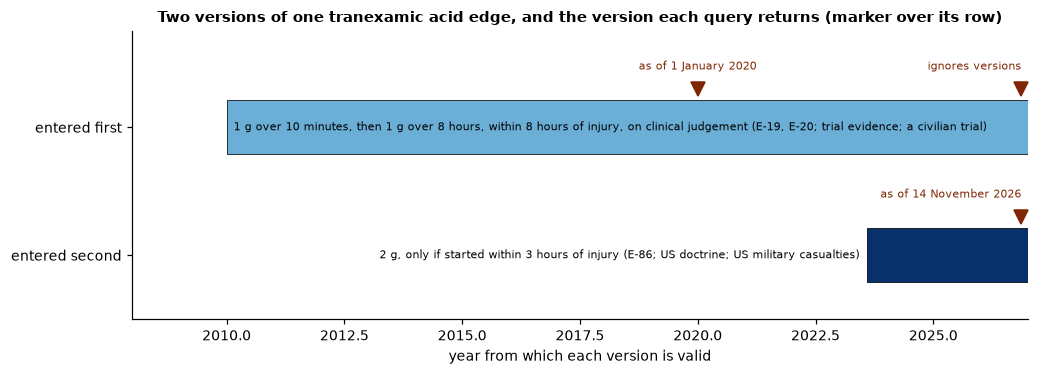

In [15]:
versions = k.care_graph().edges(src=src, dst=dst)
fig, ax = plt.subplots(figsize=(10.5, 3.4))
end = 2027.0
for y, e in zip((1, 0), versions):
    parts = [int(p) for p in e.valid_from.split("-")]
    x0 = parts[0] + ((parts[1] - 1) / 12 if len(parts) > 1 else 0)
    ax.barh(y, end - x0, left=x0, height=0.42, color=PALE if e.label == "trial evidence" else MID, edgecolor="black",
            linewidth=0.5)
    who = "a civilian trial" if "civilian" in e.population else e.population.split(" (")[0]
    words = f"{e.props['dose']}, {e.props['condition']} ({e.source}; {k.shown_label(e)}; {who})"
    if e.label == "trial evidence":
        ax.text(x0 + 0.15, y, words, va="center", fontsize=7.5)
    else:
        ax.text(x0 - 0.15, y, words, va="center", ha="right", fontsize=7.5)
queries = (("ignores versions", 2026.87, 1), ("as of 1 January 2020", 2020.0, 1), ("as of 14 November 2026", 2026.87, 0))
for name, when, row in queries:
    ax.plot(when, row + 0.3, marker="v", ms=9, color=DARK, linestyle="")
    ax.text(when, row + 0.43, name, ha="right" if when > 2025 else "center", va="bottom", fontsize=7, color=DARK)
ax.set_yticks([1, 0], ["entered first", "entered second"])
ax.set_xlim(2008, end)
ax.set_ylim(-0.5, 1.75)
ax.set_xlabel("year from which each version is valid")
ax.set_title("Two versions of one tranexamic acid edge, and the version each query returns (marker over its row)")
plt.show()

The query that ignores versions returns the first edge entered, the CRASH-2 regimen, and it would go on returning it however many later versions were added. The date-aware query returns the US guideline's 2 g within 3 hours and reports one earlier version set aside; asked as of 1 January 2020, it returns the CRASH-2 edge and reports that a later version exists.

So, the guess at the top. The system would know only if each edge carries its version and the date it holds from, and the question asks for them. Even then it knows only what someone entered: this graph holds the version of the guideline that was read, and nothing tells it whether a newer one has been published since.

### Failure two: an edge for another population

The graph holds two edges from tension pneumothorax to needle decompression. One is the recommended needle of about 5 cm, as E-104 records it. It carries the label doctrine because E-104 records the length as a recommendation; the register does not say who recommended it or for whom, so its population field reads "not stated". The other comes from E-104's own measurements, CT of 100 male military cases: a mean chest wall of 5.36 cm (SD 1.19), with an 8 cm catheter reaching in 99%. Asked for a military casualty, the population-aware query reads the two fields.

needle of 5 cm: population 'not stated in the register': population not stated
catheter of 8 cm: population 'male military personnel: CT of 100 male military cases (E-104)': holds
Under lens 01's assumed normal shape with E-104's mean and SD: a 5 cm needle reaches 38.1% of chest walls, an 8 cm catheter 98.7% (E-104 gives 99% for the catheter).


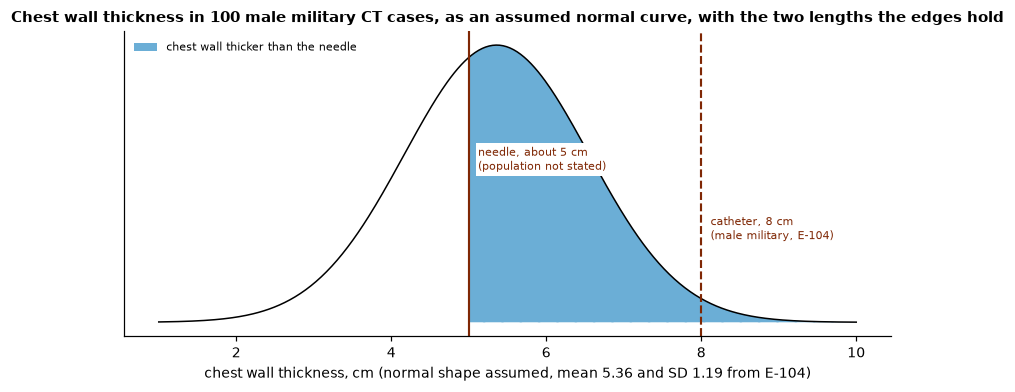

In [16]:
for e, verdict in k.population_query("injury:tension pneumothorax", "intervention:needle decompression", "military"):
    print(f"{e.props['device']} of {e.props['length_cm']:g} cm: population '{e.population}': {verdict}")
print(f"Under lens 01's assumed normal shape with E-104's mean and SD: a 5 cm needle reaches "
      f"{100 * rules.needle_reaches(rules.NEEDLE_CM):.1f}% of chest walls, an 8 cm catheter "
      f"{100 * rules.needle_reaches(rules.CATHETER_CM):.1f}% (E-104 gives 99% for the catheter).")

xs = np.linspace(1, 10, 400)
density = np.exp(-0.5 * ((xs - rules.CHEST_WALL_MEAN_CM) / rules.CHEST_WALL_SD_CM) ** 2) / (rules.CHEST_WALL_SD_CM * np.sqrt(2 * np.pi))
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(xs, density, color="black", lw=1)
ax.fill_between(xs, density, where=xs > rules.NEEDLE_CM, color=PALE, hatch="//", edgecolor="black", linewidth=0,
                label="chest wall thicker than the needle")
for cm, words in ((rules.NEEDLE_CM, "needle, about 5 cm\n(population not stated)"),
                  (rules.CATHETER_CM, "catheter, 8 cm\n(male military, E-104)")):
    ax.axvline(cm, color=DARK, lw=1.4, linestyle="-" if cm == rules.NEEDLE_CM else "--")
    ax.text(cm + 0.12, density.max() * (0.55 if cm == rules.NEEDLE_CM else 0.3), words, fontsize=7.5, color=DARK,
            bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
ax.set_xlabel("chest wall thickness, cm (normal shape assumed, mean 5.36 and SD 1.19 from E-104)")
ax.set_yticks([])
ax.legend(frameon=False, fontsize=7.5, loc="upper left")
ax.set_title("Chest wall thickness in 100 male military CT cases, as an assumed normal curve, with the two lengths the "
             "edges hold")
plt.show()

The 5 cm edge is not wrong in itself: it says what it says for a population it does not name. For a military casualty the population-aware query flags it and returns the catheter edge, whose population is E-104's male military cases. Under lens 01's assumed normal shape, which reproduces E-104's 99% for the catheter closely at 98.7%, a 5 cm needle would reach in 38.1% of chest walls. The shape is an assumption; the mean and spread are E-104's. A graph needs somewhere to say for whom an edge holds, and a query that reads it.

## Scorecard

The scorecard has seven axes (D-21). Axes 1, 2 and 6 are computed on the generator and carry the **mechanism** label; axes 3, 4 and 5 are stated; axis 7 is net benefit at a threshold of 0.10 for every lens (D-26). Net benefit judges a model by its consequences, at a threshold probability that encodes how a false alarm is weighed against a miss (E-93); here it is computed per 100 casualties as those correctly flagged less those wrongly flagged, the second weighted by the threshold over one minus it, and set beside flagging every casualty and flagging none, which scores zero.

The diagnosis column is the ranked list on the military cohort's 100,000 synthetic casualties (seed 42), scored against each casualty's true condition and, as the flag "any candidate", against need for a life-saving intervention. Fit is **native**. The baseline columns are the MPTT-24's Priority 1 against the same need, under the figure reading as published and the text reading as validated (D-24), with D-23's statement beside the rule's accuracy: The scorecard's figures are on every stream of the military cohort, disease included; the comparison with E-09 holds for the injured only, of whom 26.5% need a life-saving intervention against 47.6% Priority 1 in the military registry (E-09), so the generator's injured are a milder cohort than the one the rule was validated on (D-23). Casualties the generator has dead from bleeding before pre-hospital care are counted with the rest, as the cell below prints. The treatment column is the chain of care. Fit is **native**. The rule gives no list and no chain, so the baseline of the list and treatment rows is empty (NaN).

In [17]:
display(k.seven_axes())
obs8, tru8 = baseline.generator_sample()
print(baseline.died_before_care_note(baseline.died_before_care_count(obs8, tru8),
                                     "the 100,000 casualties behind the diagnosis and baseline columns") + ".")

,diagnosis: ranked candidates from findings,"baseline: MPTT-24, figure (as published)","baseline: MPTT-24, text (as validated)",treatment: the chain of care
axis,,,,
1 Discrimination (mechanism),"Flag when the list holds any candidate, before hospital: sensitivity 95.67%, specificity 32.83% against need for a life-saving intervention, on the military cohort's 100,000 synthetic casualties; of the 16,704 casualties with a condition needing a life-saving intervention, the true condition is first and alone for 21.7%, first alone or tied for 85.3%, and in the list for 95.0%. Sensitivity less the rule's (figure) is higher: the difference runs from +35.2 to +36.4 points across 20 seeds; specificity less the rule's is lower: the difference runs from -46.4 to -45.7 points across 20 seeds","sensitivity 60.0%, specificity 78.6% against need. The scorecard's figures are on every stream of the military cohort, disease included; the comparison with E-09 holds for the injured only, of whom 26.5% need a life-saving intervention against 47.6% Priority 1 in the military registry (E-09), so the generator's injured are a milder cohort than the one the rule was validated on (D-23). The generator's physiology is an assumption, tuned until the rule landed within 0.05 of E-09's accuracy, which was measured on first recorded hospital respiratory rate and registry GCS, not at the point of injury","sensitivity 61.4%, specificity 77.8% against need","Not a classifier: the chain from the point of injury for each condition, and the share of the generator's casualties with it whose assumed time to the nearest echelon holding the intervention is within the timeline on the edge into that echelon (E-42), each timeline read here as time from injury, an assumption. The timeline belongs to the edge, as E-42 states it, and is not a target for each intervention. extremity haemorrhage: tranexamic acid at Role 1, 55.4% within its timeline, blood: whole blood, otherwise components at about 1:1:1 at Role 1, 55.4% within its timeline; junctional haemorrhage: tranexamic acid at Role 1, 55.1% within its timeline, blood: whole blood, otherwise components at about 1:1:1 at Role 1, 55.1% within its timeline, surgery at Role 2, 58.2% within its timeline; truncal haemorrhage: tranexamic acid at Role 1, 55.7% within its timeline, blood: whole blood, otherwise components at about 1:1:1 at Role 1, 55.7% within its timeline, surgery at Role 2, 60.3% within its timeline; septic shock: antibiotics and fluids at Role 2, 58.1% within its timeline. Times to pre-hospital care and to Role 2 are the generator's assumptions, drawn for every casualty, including those it has dead from bleeding before then; time to pre-hospital care stands in for reaching Role 1, and the generator holds no time for care at the point of injury or for reaching Role 3"
2 Calibration (mechanism),"Brier 0.567, where lower is better; it flags 55.2 points more than are in need. A list gives no probability, so the Brier score is the share misclassified. Brier less the rule's, where lower is better, is higher: the difference runs from +0.320 to +0.328 across 20 seeds","Brier 0.245, where lower is better; it flags 11.2 points more than are in need. A rule gives no probability, so the Brier score is the share misclassified","Brier 0.249, where lower is better; it flags 12.1 points more than are in need. A rule gives no probability, so the Brier score is the share misclassified",Does not apply: a chain gives no probability
3 Uncertainty expressed,"None as a probability. A ranked list, with ties shown as ties; every edge carries a label saying what kind of claim it is, not how sure",None: a priority,None: a priority,"None as a probability. Each edge carries its label, version, date and population, and the query says when a version or population was set aside"
4 What it needed,"A hand-built graph and no labelled cases: 28 suggests edges, every one an assumption written from what the generator's code does",Rules only (E-08)

482 of the 100,000 casualties behind the diagnosis and baseline columns died from bleeding before pre-hospital care in the generator, without tranexamic acid, and are included.


In [18]:
card = pd.DataFrame([vars(row) for row in k.LENS.scorecard()])
with pd.option_context("display.precision", 4):     # as the rows hold them, so nothing is rounded twice
    display(card[["case", "metric", "value", "baseline", "label", "fit"]])

,case,metric,value,baseline,label,fit
0,diagnosis,"sensitivity, any candidate against need for a life-saving intervention, scan before hospital",0.9567,0.5999,mechanism,native
1,diagnosis,"specificity, any candidate against need for a life-saving intervention, scan before hospital",0.3283,0.7856,mechanism,native
2,diagnosis,"Brier score, where lower is better, any candidate against need for a life-saving intervention, scan before hospital",0.5667,0.2454,mechanism,native
3,diagnosis,"share flagged minus share in need, any candidate against need for a life-saving intervention, scan before hospital",0.5522,0.1118,mechanism,native
4,diagnosis,"true condition first, alone, among casualties with a condition needing a life-saving intervention, scan before hospital",0.2171,NaN,mechanism,native
5,diagnosis,"true condition first, alone or tied, among casualties with a condition needing a life-saving intervention, scan before hospital",0.8531,NaN,mechanism,native
6,diagnosis,"true condition anywhere in the list, among casualties with a condition needing a life-saving intervention, scan before hospital",0.9500,NaN,mechanism,native
7,diagnosis,"sensitivity, any candidate against need for a life-saving intervention, scan in hospital",0.9616,0.5999,mechanism,native
8,diagnosis,"specificity, any candidate against need for a life-saving intervention, scan in hospital",0.3285,0.7856,mechanism,native
9,diagnosis,"Brier score, where lower is better, any candidate against need for a life-saving intervention, scan in hospital",0.5658,0.2454,mechanism,native


Two rows carry the lesson.

**Diagnosis.** The list holds the true condition for 95.0% of the casualties with one, and as a flag catches 95.7% of those in need against the rule's 60.0%, but flags 71.9% of all casualties and its specificity is 32.8%. The scorecard's figures are on every stream of the military cohort, disease included; the comparison with E-09 holds for the injured only, of whom 26.5% need a life-saving intervention against 47.6% Priority 1 in the military registry (E-09), so the generator's injured are a milder cohort than the one the rule was validated on (D-23). At a threshold of 0.10, where a miss is weighed nine times a false alarm, that trade scores a net benefit of 9.8 per 100 against the rule's 8.0; the threshold is an assumption, and the difference, 1.6 to 1.9 per 100 across 20 seeds, rests on it. Either way the graph's answer is a list with reasons, and every reason is an edge someone wrote.

**Treatment.** The chain names where each intervention is first held and the timeline on the edge into it. On the generator's assumed clock, little more than half the casualties with each condition have a time to that echelon within the timeline. The chain is not a flag, so axis 7 does not apply; what it offers a decision is a bound on the options.

## The brain analogy, and where it breaks

**What it resembles.** Schema and semantic memory. People hold knowledge as connected concepts: a medic who hears "free fluid" thinks of bleeding into the abdomen, then of surgery, then of where the surgeon is, without working it out from the beginning each time. Following the connections is quick, and it is only as good as the connections laid down.

**Where it breaks.** Human association is graded and depends on context: the strength of a link changes with experience and with the situation, and the same cue can bring different things to mind on different days. The graph's edges are all or nothing, the weights here are counted from the graph's own structure, and an edge stays exactly as it was entered until someone changes it. The graph retrieves what was put there. It does not reason.

**Where it leads.** Grounding a language model in curated sources is one use for a maintained, sourced graph. On 314 clinical questions in nine specialties, rated by ten clinicians, a retrieval-augmented model was rated significantly better than standard models for factuality, completeness, preference and safety; the register records no effect sizes (E-111). Retrieval-augmented generation and graph learning belong to other projects and are not built here.